# 🇧🇷 Brazil 2026 Presidential Election — Round Comparison Map

**Target metric per municipality:**

$$\Delta = (\text{Lula}_{R2} - \text{Lula}_{R1}) - (\text{Flávio}_{R2} - \text{Flávio}_{R1})$$

normalised by total valid votes in each municipality.

- **Red** → Lula gained more votes relative to Flávio between rounds
- **Blue** → Flávio gained more votes relative to Lula between rounds

> **Note (Oct 2026):** Round 2 happened on 25 Oct. TSE publishes per-section bulk CSVs
> within a few days. The notebook auto-detects which rounds are present and shows the
> full swing map once Round-2 data is available at the same URL. Until then it renders
> the Round-1 vote-share difference.

In [91]:
import zipfile, json, unicodedata, re, requests
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
print("Ready.")

Ready.


## 1. Download TSE Presidential Section Data

In [92]:
def download_file(url: str, dest: Path, label: str = "") -> None:
    if dest.exists():
        print(f"✓ cached: {dest.name}  ({dest.stat().st_size / 1e6:.1f} MB)")
        return
    print(f"↓ {label or dest.name} …", end=" ", flush=True)
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=2 ** 20):
                f.write(chunk)
    print(f"done  ({dest.stat().st_size / 1e6:.1f} MB)")

PRES_URL = (
    "https://cdn.tse.jus.br/estatistica/sead/odsele"
    "/votacao_secao/votacao_secao_2026_BR.zip"
)
PRES_ZIP = DATA_DIR / "votacao_secao_2026_BR.zip"
download_file(PRES_URL, PRES_ZIP, "TSE presidential sections 2026")

✓ cached: votacao_secao_2026_BR.zip  (161.6 MB)


## 2. Load & Filter Candidates

In [93]:
with zipfile.ZipFile(PRES_ZIP) as z:
    csv_name = next(n for n in z.namelist() if n.endswith(".csv"))
    print("Reading:", csv_name, "…", end=" ", flush=True)
    with z.open(csv_name) as f:
        df_raw = pd.read_csv(
            f, encoding="latin-1", sep=";", dtype=str, low_memory=False
        )
print(f"done  {len(df_raw):,} rows")

df = df_raw.copy()
df["NR_TURNO"]   = df["NR_TURNO"].str.strip()
df["NM_VOTAVEL"] = df["NM_VOTAVEL"].str.upper().str.strip()
df["QT_VOTOS"]   = pd.to_numeric(df["QT_VOTOS"], errors="coerce").fillna(0)

lula_mask   = df["NM_VOTAVEL"].str.contains(r"LULA", na=False)
flavio_mask = df["NM_VOTAVEL"].str.contains(r"FL[AÁ]VIO.*BOLSONARO|BOLSONARO.*FL[AÁ]VIO", na=False, regex=True)
if not flavio_mask.any():
    flavio_mask = df["NM_VOTAVEL"].str.contains(r"FLAVIO|BOLSONARO", na=False)

print(f"Lula   : {df.loc[lula_mask,   'NM_VOTAVEL'].iloc[0]}")
print(f"Flávio : {df.loc[flavio_mask, 'NM_VOTAVEL'].iloc[0]}")
print(f"Rounds : {sorted(df['NR_TURNO'].unique().tolist())}")

Reading: votacao_secao_2026_BR.csv … done  3,800,511 rows
Lula   : LUIZ INÁCIO LULA DA SILVA
Flávio : FLAVIO NANTES BOLSONARO
Rounds : ['1']


## 3. Aggregate by Municipality & Compute Metric

In [94]:
KEY = ["CD_MUNICIPIO", "NM_MUNICIPIO", "SG_UF", "NR_TURNO"]
lula_agg   = df[lula_mask].groupby(KEY)["QT_VOTOS"].sum().reset_index().rename(columns={"QT_VOTOS": "lula"})
flavio_agg = df[flavio_mask].groupby(KEY)["QT_VOTOS"].sum().reset_index().rename(columns={"QT_VOTOS": "flavio"})

# Total valid votes per municipality per round (all candidates, excludes blank and null).
# TSE section CSV labels: "VOTO BRANCO" and "VOTO NULO"
invalid_mask = df["NM_VOTAVEL"].str.contains(r"BRANCO|NULO", na=False)
valid_agg = (
    df[~invalid_mask]
    .groupby(KEY)["QT_VOTOS"]
    .sum()
    .reset_index()
    .rename(columns={"QT_VOTOS": "valid"})
)
print(f"Valid candidate rows: {(~invalid_mask).sum():,}  "
      f"(blank/null excluded: {invalid_mask.sum():,})")

df_mun = lula_agg.merge(flavio_agg, on=KEY, how="outer").fillna(0)

# pivot: one row per municipality, columns lula_1 / lula_2 / flavio_1 / flavio_2
df_mun = df_mun.pivot_table(
    index=["CD_MUNICIPIO", "NM_MUNICIPIO", "SG_UF"],
    columns="NR_TURNO",
    values=["lula", "flavio"],
    aggfunc="sum",
    fill_value=0,
).reset_index()
df_mun.columns = [f"{a}_{b}" if b else a for a, b in df_mun.columns]

# pivot valid votes and merge in (values as list to force MultiIndex columns)
valid_pivot = valid_agg.pivot_table(
    index=["CD_MUNICIPIO", "NM_MUNICIPIO", "SG_UF"],
    columns="NR_TURNO",
    values=["valid"],
    aggfunc="sum",
    fill_value=0,
).reset_index()
valid_pivot.columns = [f"valid_{b}" if b else a for a, b in valid_pivot.columns]
df_mun = df_mun.merge(valid_pivot, on=["CD_MUNICIPIO", "NM_MUNICIPIO", "SG_UF"], how="left")

print("Columns:", df_mun.columns.tolist())
print(f"Municipalities: {len(df_mun):,}")

rounds = df["NR_TURNO"].unique().tolist()
has_r2 = "2" in rounds

if has_r2:
    print("\n✓ Both rounds — computing SWING metric")
    share_r1 = (df_mun["lula_1"] - df_mun["flavio_1"]) / df_mun["valid_1"] * 100
    share_r2 = (df_mun["lula_2"] - df_mun["flavio_2"]) / df_mun["valid_2"] * 100
    df_mun["metric"] = share_r2 - share_r1
    metric_label = "variação na vantagem de Lula (p.p. dos votos válidos)"
    title_main   = "Mudança na vantagem de Lula: 2° turno − 1° turno  por município"
    subtitle     = "Vermelho: Lula melhorou relativamente  |  Azul: Flávio melhorou relativamente"
else:
    print("\n⚠️  Round 1 only — showing vote-share difference (R2 data coming soon)")
    df_mun["metric"] = np.where(
        df_mun["valid_1"] > 0,
        (df_mun["lula_1"] - df_mun["flavio_1"]) / df_mun["valid_1"] * 100,
        np.nan,
    )
    metric_label = "diferença Lula − Flávio (% dos votos válidos, 1° turno)"
    title_main   = "Lula − Flávio por município  •  1° turno 2026"
    subtitle     = "Vermelho: Lula à frente  |  Azul: Flávio à frente  (dados do 1° turno)"

print(df_mun[["NM_MUNICIPIO", "metric"]].describe().round(2))

Valid candidate rows: 2,835,340  (blank/null excluded: 965,171)
Columns: ['CD_MUNICIPIO', 'NM_MUNICIPIO', 'SG_UF', 'flavio_1', 'lula_1', 'valid_1']
Municipalities: 5,716

⚠️  Round 1 only — showing vote-share difference (R2 data coming soon)
        metric
count  5716.00
mean      3.26
std      36.75
min     -90.86
25%     -27.37
50%      -2.46
75%      37.39
max     100.00


## 4. Download Geometries

In [95]:
# Geometry source: tbrugz/geodata-br (IBGE codes in 'id' property, names in 'name')
MUN_GEO_URL   = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-100-mun.json"
STATE_GEO_URL = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
MUN_GEO_FILE   = DATA_DIR / "municipios_geo.geojson"
STATE_GEO_FILE = DATA_DIR / "estados_geo.geojson"

download_file(MUN_GEO_URL,   MUN_GEO_FILE,   "municipality geometries (tbrugz/geodata-br)")
download_file(STATE_GEO_URL, STATE_GEO_FILE, "state geometries")

gdf_mun    = gpd.read_file(MUN_GEO_FILE)
gdf_states = gpd.read_file(STATE_GEO_FILE)
print("Municipality GDF:", gdf_mun.shape, "cols:", gdf_mun.columns.tolist()[:5])
print("State GDF       :", gdf_states.shape)

✓ cached: municipios_geo.geojson  (22.5 MB)
✓ cached: estados_geo.geojson  (3.4 MB)
Municipality GDF: (5564, 4) cols: ['id', 'name', 'description', 'geometry']
State GDF       : (27, 9)


## 5. Build Municipality Crosswalk (TSE code → IBGE id via name matching)

In [96]:
# IBGE state prefix (first 2 digits of 7-digit IBGE code) → UF sigla
IBGE_UF = {
    "11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA",
    "16": "AP", "17": "TO", "21": "MA", "22": "PI", "23": "CE",
    "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE",
    "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP",
    "41": "PR", "42": "SC", "43": "RS", "50": "MS", "51": "MT",
    "52": "GO", "53": "DF",
}

def normalise(s: str) -> str:
    s = str(s).upper().strip()
    s = unicodedata.normalize("NFD", s)
    s = re.sub(r"[\u0300-\u036f]", "", s)
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

# Build name+UF → IBGE id lookup from the GeoJSON
ibge_lookup = {}
for _, row in gdf_mun.iterrows():
    ibge_id = str(row.get("id", row.get("codarea", "")))
    name    = str(row.get("name", row.get("NM_MUNICIPIO", "")))
    uf      = IBGE_UF.get(ibge_id[:2], "")
    key     = normalise(name) + "|" + uf
    ibge_lookup[key] = ibge_id

print(f"Lookup entries: {len(ibge_lookup):,}")
print("Sample:", dict(list(ibge_lookup.items())[:3]))

df_mun["key"]     = df_mun["NM_MUNICIPIO"].apply(normalise) + "|" + df_mun["SG_UF"]
df_mun["ibge_id"] = df_mun["key"].map(ibge_lookup)

hit = df_mun["ibge_id"].notna().sum()
print(f"\nCrosswalk hit rate: {hit / len(df_mun):.1%}  ({hit:,} / {len(df_mun):,})")

misses = df_mun[df_mun["ibge_id"].isna()][["NM_MUNICIPIO", "SG_UF"]].head(10)
if len(misses):
    print("Sample misses:", misses.to_string(index=False))

Lookup entries: 5,564
Sample: {'ALTA FLORESTA D OESTE|RO': '1100015', 'ARIQUEMES|RO': '1100023', 'CABIXI|RO': '1100031'}

Crosswalk hit rate: 96.9%  (5,537 / 5,716)
Sample misses:          NM_MUNICIPIO SG_UF
              NAZÁRIA    PI
              ITAPAJÉ    CE
                 ASSÚ    RN
                 AREZ    RN
         CAMPO GRANDE    RN
            BOA SAÚDE    RN
         SERRA CAIADA    RN
        JOCA CLAUDINO    PB
SÃO VICENTE DO SERIDÓ    PB
               TACIMA    PB


In [97]:
# Merge metric into geometry
geo_id_col = "id" if "id" in gdf_mun.columns else "codarea"
gdf_mun["ibge_id"] = gdf_mun[geo_id_col].astype(str)

merged = gdf_mun.merge(
    df_mun[["ibge_id", "metric"]].dropna(subset=["ibge_id"]),
    on="ibge_id",
    how="left",
)
n = merged["metric"].notna().sum()
print(f"Matched {n:,} / {len(merged):,}  ({n / len(merged):.1%})")

Matched 5,537 / 5,564  (99.5%)


## 6. Draw the Map

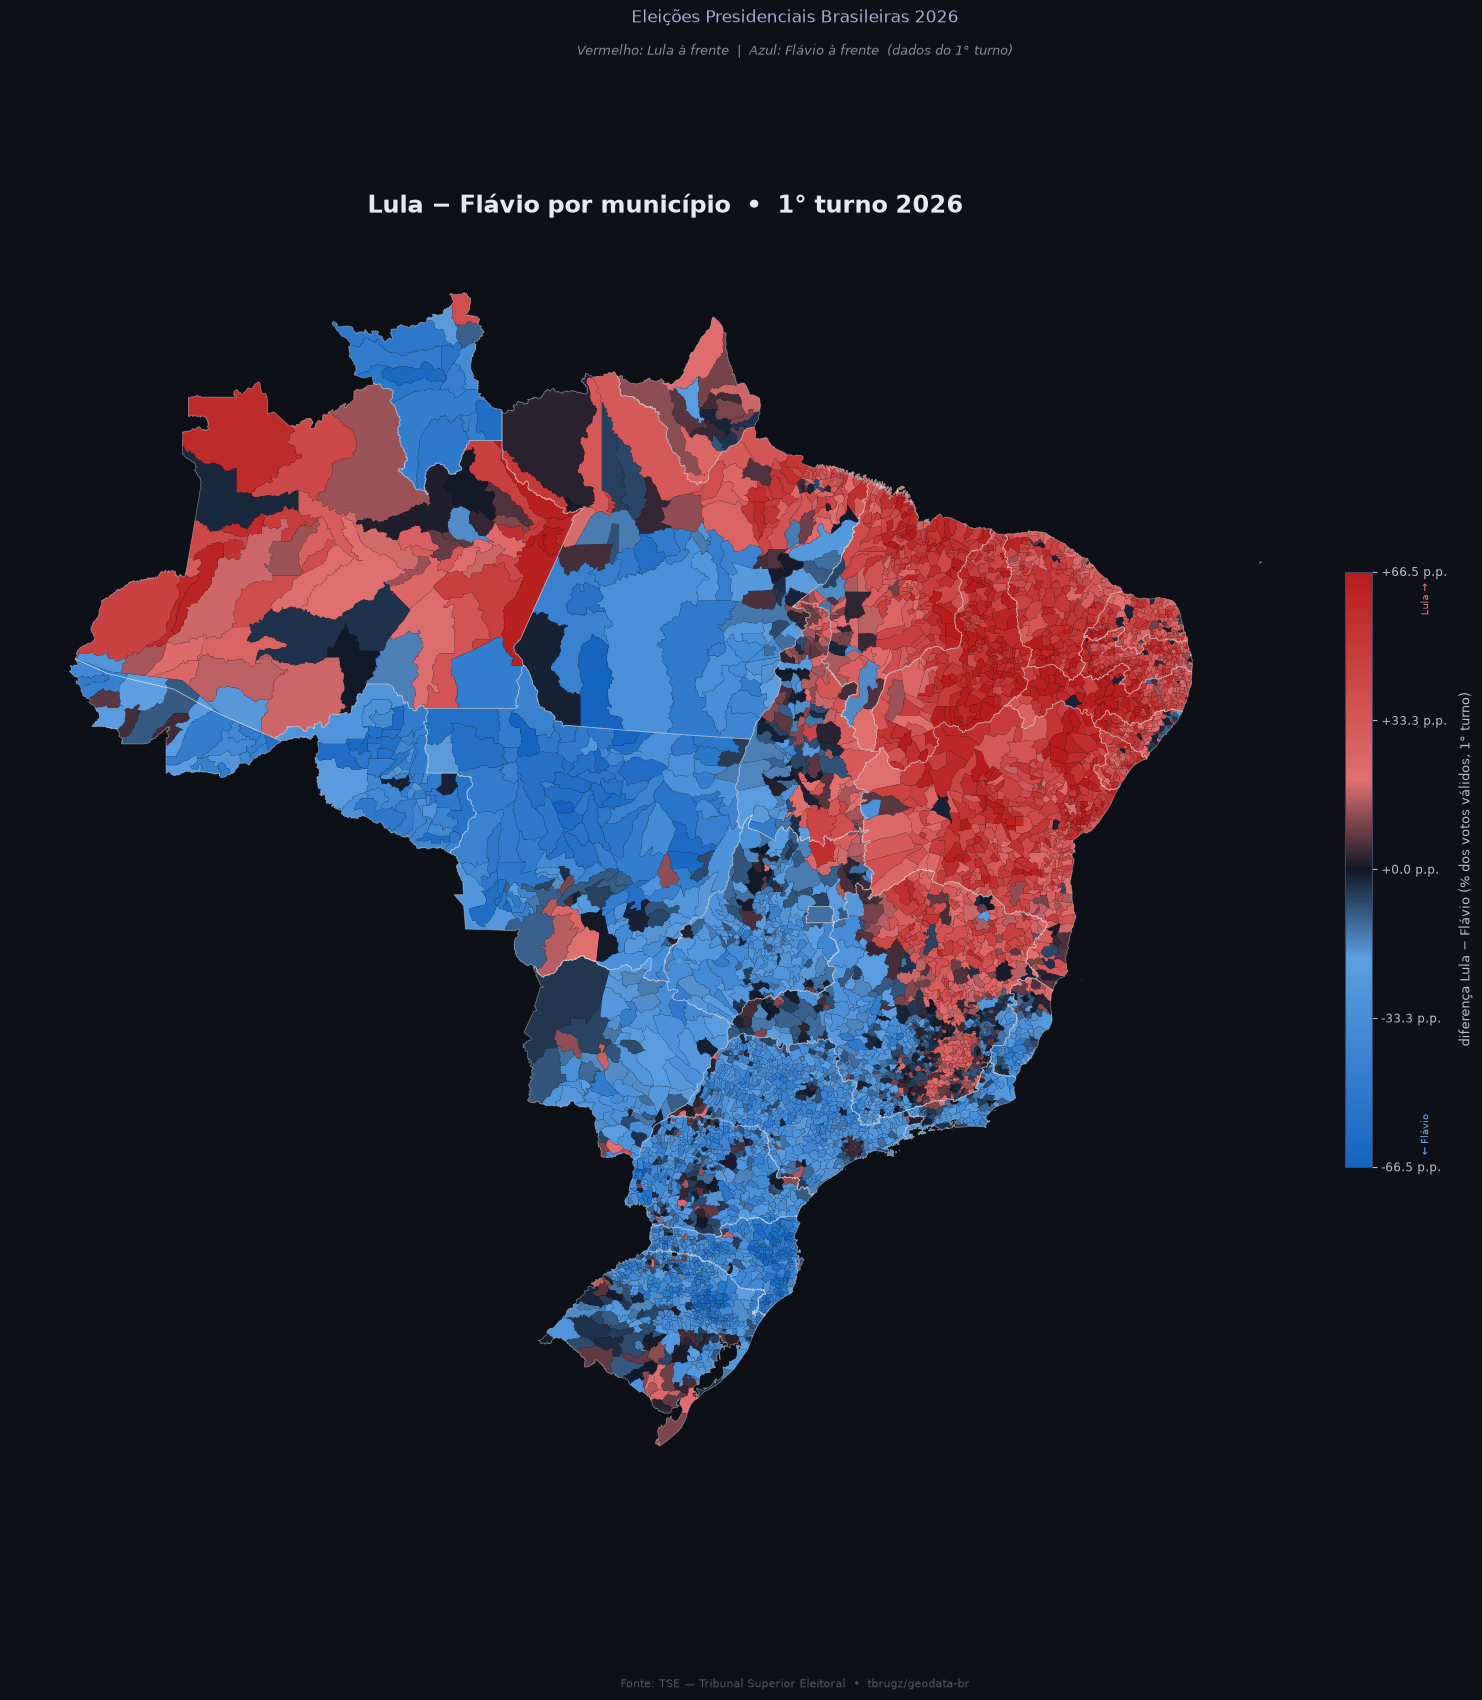

Saved election_map.png


In [98]:
cmap = LinearSegmentedColormap.from_list(
    "br_swing",
    [
        (0.00, "#1565C0"),
        (0.35, "#5C9EE0"),
        (0.50, "#111827"),
        (0.65, "#E07070"),
        (1.00, "#B71C1C"),
    ],
)

col  = "metric"
vmax = float(np.nanquantile(merged[col].abs(), 0.97))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

BG = "#0d1117"
fig, ax = plt.subplots(figsize=(16, 18), facecolor=BG)
ax.set_facecolor(BG)

merged.plot(
    column=col, ax=ax, cmap=cmap, norm=norm,
    linewidth=0.03, edgecolor=BG,
    missing_kwds={"color": "#1a2035", "label": "Sem dados"},
)
gdf_states.boundary.plot(ax=ax, color="white", linewidth=0.55, alpha=0.40)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="vertical",
                    shrink=0.38, aspect=22, pad=0.015)
cbar.outline.set_edgecolor("#444466")
cbar.ax.tick_params(colors="#bbbbcc", labelsize=8.5)

ticks = np.linspace(-vmax, vmax, 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{v:+.1f} p.p." for v in ticks])
cbar.set_label(metric_label, color="#bbbbcc", fontsize=9, labelpad=8)
cbar.ax.text(2.8, 0.02, "← Flávio", transform=cbar.ax.transAxes,
             va="bottom", ha="left", fontsize=7.5, color="#7aa8e0", rotation=90)
cbar.ax.text(2.8, 0.98, "Lula →",   transform=cbar.ax.transAxes,
             va="top",    ha="left", fontsize=7.5, color="#e07a7a", rotation=90)

ax.set_title(title_main, color="#e8e8f0", fontsize=17, fontweight="bold", pad=16)
fig.text(0.5, 0.932, "Eleições Presidenciais Brasileiras 2026",
         ha="center", color="#aaaacc", fontsize=12)
fig.text(0.5, 0.914, subtitle,
         ha="center", color="#888899", fontsize=9.5, style="italic")

ax.axis("off")
plt.tight_layout(rect=[0, 0.018, 1, 0.905])
fig.text(0.5, 0.007, "Fonte: TSE — Tribunal Superior Eleitoral  •  tbrugz/geodata-br",
         ha="center", color="#555566", fontsize=8)

plt.savefig("election_map.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.show()
print("Saved election_map.png")

---
## 7. State-Level Swing Map (Both Rounds Available via TSE API)

The TSE live-results API already has per-state final totals for both rounds.

**Metric:** `(Lula% R2 − Flávio% R2) − (Lula% R1 − Flávio% R1)`

where each `%` is share of **total valid votes** in that round (all candidates, excluding blank and null).  
Equivalent to subtracting the R1 lead map from the R2 lead map.

In [99]:
ALL_UFS = [
    "AC","AL","AM","AP","BA","CE","DF","ES","GO","MA",
    "MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN",
    "RO","RR","RS","SC","SE","SP","TO",
]

def fetch_state_votes(uf: str, election_code: int) -> tuple[dict[str, int], int]:
    """Return ({candidate_name: votes}, total_valid_votes) for one state and one round.
    Total valid votes = sum of all candidate votes excluding any blank or null entry."""
    ec  = str(election_code).zfill(6)
    url = (
        f"https://resultados.tse.jus.br/oficial/ele2026"
        f"/{election_code}/dados/{uf.lower()}"
        f"/{uf.lower()}-c0001-e{ec}-u.json"
    )
    r = requests.get(url, timeout=20)
    r.raise_for_status()
    data = r.json()
    result = {}
    total_valid = 0
    for agr in data.get("carg", [{}])[0].get("agr", []):
        for par in agr.get("par", []):
            for c in par.get("cand", []):
                nm    = c["nm"].upper().strip()
                votes = int(str(c["vap"]).replace(",", ""))
                result[nm] = votes
                if "BRANCO" not in nm and "NULO" not in nm:
                    total_valid += votes
    return result, total_valid

rows = []
for uf in ALL_UFS:
    r1, valid_1 = fetch_state_votes(uf, 6257)   # 1st round
    r2, valid_2 = fetch_state_votes(uf, 6258)   # 2nd round

    lula_key   = next((k for k in r1 if "LULA"   in k), None)
    flavio_key = next((k for k in r1 if "FLAVIO" in k or "FLÁVIO" in k), None)

    rows.append({
        "uf":       uf,
        "lula_1":   r1.get(lula_key,   0),
        "lula_2":   r2.get(lula_key,   r2.get(next((k for k in r2 if "LULA" in k), ""), 0)),
        "flavio_1": r1.get(flavio_key, 0),
        "flavio_2": r2.get(flavio_key, r2.get(next((k for k in r2 if "FLAVIO" in k or "FLÁVIO" in k), ""), 0)),
        "valid_1":  valid_1,
        "valid_2":  valid_2,
    })
    print(f"  {uf}: L1={rows[-1]['lula_1']:>9,}  L2={rows[-1]['lula_2']:>9,}  "
          f"F1={rows[-1]['flavio_1']:>9,}  F2={rows[-1]['flavio_2']:>9,}  "
          f"V1={rows[-1]['valid_1']:>9,}  V2={rows[-1]['valid_2']:>9,}")

df_states = pd.DataFrame(rows)

# Lead as % of total valid votes in each round, then difference.
# Equivalent to subtracting the two per-round percentage maps.
df_states["share_r1"] = (df_states["lula_1"] - df_states["flavio_1"]) / df_states["valid_1"] * 100
df_states["share_r2"] = (df_states["lula_2"] - df_states["flavio_2"]) / df_states["valid_2"] * 100
df_states["swing_pct"] = df_states["share_r2"] - df_states["share_r1"]

print("\n", df_states[["uf","share_r1","share_r2","swing_pct"]].sort_values("swing_pct").to_string(index=False))

  AC: L1=  134,770  L2=  144,513  F1=  302,807  F2=  287,715  V1=  469,066  V2=  432,228
  AL: L1=  995,459  L2=1,152,621  F1=  735,718  F2=  744,140  V1=1,818,856  V2=1,896,761
  AM: L1=1,046,996  L2=1,145,783  F1=  976,764  F2=  975,245  V1=2,170,763  V2=2,121,028
  AP: L1=  212,503  L2=  222,968  F1=  212,278  F2=  198,674  V1=  464,858  V2=  421,642
  BA: L1=5,664,771  L2=6,485,258  F1=2,442,585  F2=2,608,761  V1=8,560,291  V2=9,094,019
  CE: L1=3,555,263  L2=4,036,124  F1=1,756,850  F2=1,819,478  V1=5,617,814  V2=5,855,602
  DF: L1=  675,627  L2=  825,224  F1=  909,616  F2=  979,542  V1=1,772,808  V2=1,804,766
  ES: L1=  850,028  L2=1,001,965  F1=1,233,194  F2=1,294,504  V1=2,251,078  V2=2,296,469
  GO: L1=1,188,880  L2=1,585,555  F1=2,051,888  F2=2,345,334  V1=3,827,823  V2=3,930,889
  MA: L1=2,566,301  L2=2,808,231  F1=1,239,040  F2=1,229,971  V1=4,010,439  V2=4,038,202
  MG: L1=5,188,936  L2=6,351,099  F1=5,777,548  F2=6,241,786  V1=11,976,235  V2=12,592,885
  MS: L1=  516,855 

In [104]:
states = [("Bahia", "BA"), ("Rio de Janeiro", "RJ"), ("São Paulo", "SP"), ("Minas Gerais", "MG")]
verbose = False
for name, label in states:
    data = df_states[df_states["uf"] == label].iloc[0]
    print(f"{name}")
    if verbose:
        print(f"  R1: Lula {data['lula_1']:>10,.0f}  Flávio {data['flavio_1']:>10,.0f}  válidos {data['valid_1']:>10,.0f}")
        print(f"  R2: Lula {data['lula_2']:>10,.0f}  Flávio {data['flavio_2']:>10,.0f}  válidos {data['valid_2']:>10,.0f}")
    print(f"  Lula%  R1: {data['lula_1']/data['valid_1']*100:.2f}%   R2: {data['lula_2']/data['valid_2']*100:.2f}%")
    print(f"  Flávio% R1: {data['flavio_1']/data['valid_1']*100:.2f}%   R2: {data['flavio_2']/data['valid_2']*100:.2f}%")
    if verbose:
        print(f"  Lead R1: {(data['lula_1']-data['flavio_1'])/data['valid_1']*100:+.2f} p.p.")
        print(f"  Lead R2: {(data['lula_2']-data['flavio_2'])/data['valid_2']*100:+.2f} p.p.")
    print(f"  Swing:   {data['swing_pct']:+.2f} p.p.")

Bahia
  Lula%  R1: 66.17%   R2: 71.31%
  Flávio% R1: 28.53%   R2: 28.69%
  Swing:   +4.99 p.p.
Rio de Janeiro
  Lula%  R1: 39.41%   R2: 46.90%
  Flávio% R1: 53.01%   R2: 53.10%
  Swing:   +7.39 p.p.
São Paulo
  Lula%  R1: 38.20%   R2: 46.15%
  Flávio% R1: 51.93%   R2: 53.85%
  Swing:   +6.04 p.p.
Minas Gerais
  Lula%  R1: 43.33%   R2: 50.43%
  Flávio% R1: 48.24%   R2: 49.57%
  Swing:   +5.78 p.p.


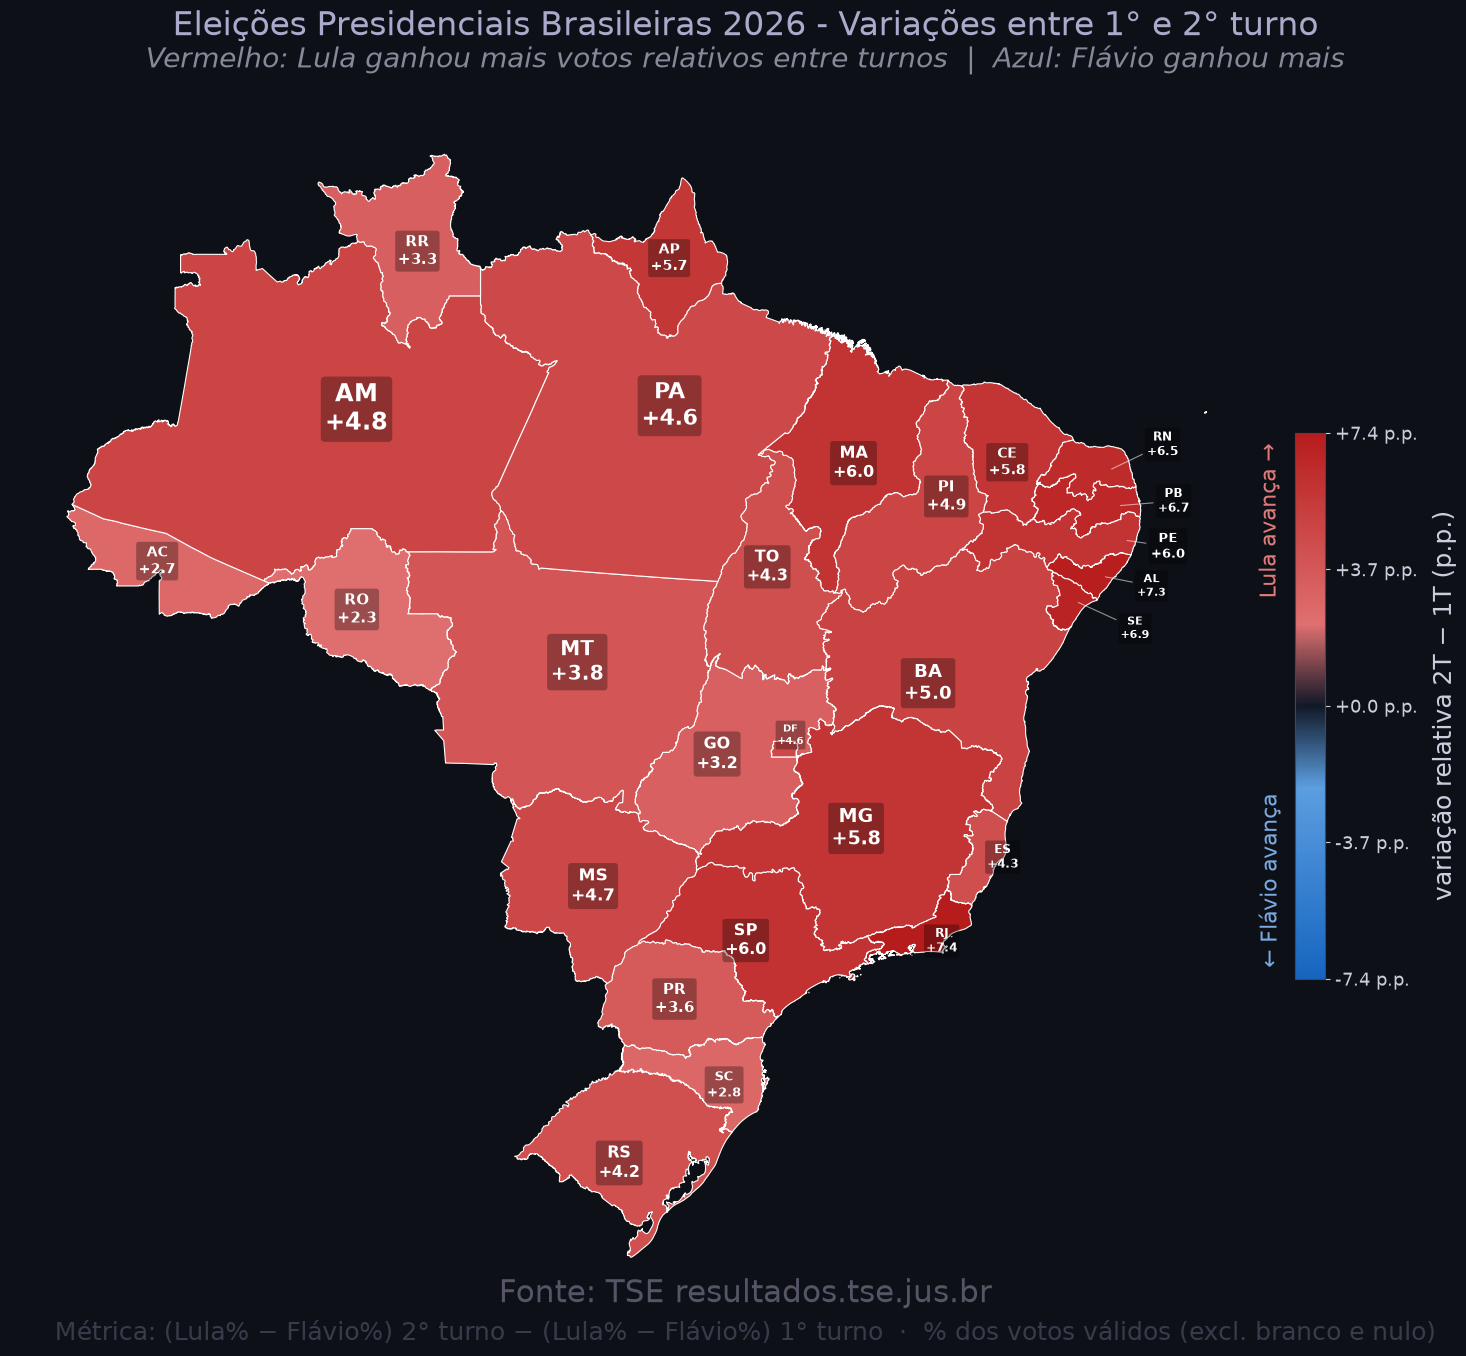

Saved election_map_states.png


In [101]:
import numpy as np

# Merge with state geometries
gdf_state_map = gdf_states.merge(df_states, left_on="sigla", right_on="uf", how="left")

# Compute state areas for font scaling
gdf_state_map_proj = gdf_state_map.to_crs("EPSG:5641")
gdf_state_map["area_km2"] = gdf_state_map_proj.geometry.area / 1e6

# Map area -> font size: sqrt scaling, clamped between 7.5 and 17
a = gdf_state_map["area_km2"]
fs_raw = 7.5 + 9.5 * (np.sqrt(a) - np.sqrt(a.min())) / (np.sqrt(a.max()) - np.sqrt(a.min()))
gdf_state_map["fontsize"] = fs_raw.clip(7.5, 17)

vmax_s = float(gdf_state_map["swing_pct"].abs().max())
norm_s = TwoSlopeNorm(vmin=-vmax_s, vcenter=0, vmax=vmax_s)

BG = "#0d1117"
fig2, ax2 = plt.subplots(figsize=(16, 14), facecolor=BG)
ax2.set_facecolor(BG)

gdf_state_map.plot(
    column="swing_pct", ax=ax2, cmap=cmap, norm=norm_s,
    linewidth=0.8, edgecolor="#ffffff",
    missing_kwds={"color": "#1a2035"},
)

# States with labels placed offshore (in the Atlantic) with a thin leader line.
# xy_offset nudges the arrow tip away from the representative point toward the coast.
OFFSHORE = {
    "RN": {"xytext": (-34.0, -5.0),  "xy_offset": (0.7,  0.0)},
    "PB": {"xytext": (-33.6, -7.0),  "xy_offset": (1.1,  0.0)},
    "PE": {"xytext": (-33.8, -8.6),  "xy_offset": (2.5,  0.0)},
    "AL": {"xytext": (-34.4, -10.0), "xy_offset": (0.5,  0.0)},
    "SE": {"xytext": (-35.0, -11.5), "xy_offset": (0.0,  0.0)},
}

# Small nudges for other crowded states
nudge = {
    "CE": (-0.3, -0.3),
    "ES": ( 0.6,  0.0), "RJ": ( 0.0, -0.5), "DF": ( 0.2,  0.5),
}

for _, row in gdf_state_map.iterrows():
    if pd.isna(row.get("swing_pct")):
        continue
    pt   = row.geometry.representative_point()
    val  = row["swing_pct"]
    sign = "+" if val >= 0 else ""
    fs   = row["fontsize"]
    label = f"{row['sigla']}\n{sign}{val:.1f}"
    sig  = row["sigla"]

    if sig in OFFSHORE:
        cfg = OFFSHORE[sig]
        ax2.annotate(
            label,
            xy=(pt.x + cfg["xy_offset"][0], pt.y + cfg["xy_offset"][1]),
            xytext=cfg["xytext"],
            ha="center", va="center",
            fontsize=max(fs, 12), color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="black",
                      alpha=0.30, linewidth=0),
            arrowprops=dict(arrowstyle="-", color="white", lw=0.8, alpha=0.55),
        )
    else:
        dx, dy = nudge.get(sig, (0, 0))
        ax2.annotate(
            label,
            xy=(pt.x + dx, pt.y + dy), ha="center", va="center",
            fontsize=fs, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="black",
                      alpha=0.30, linewidth=0),
        )

# Colorbar
sm2 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_s)
sm2.set_array([])
cbar2 = fig2.colorbar(sm2, ax=ax2, shrink=0.45, aspect=18, pad=0.02)
cbar2.outline.set_edgecolor("#444466")
cbar2.ax.tick_params(colors="#ccccdd", labelsize=13)
ticks2 = np.linspace(-vmax_s, vmax_s, 5)
cbar2.set_ticks(ticks2)
cbar2.set_ticklabels([f"{v:+.1f} p.p." for v in ticks2])
cbar2.set_label("variação relativa 2T − 1T (p.p.)", color="#ccccdd", fontsize=18, labelpad=10)
cbar2.ax.text(-1.2, 0.02, "← Flávio avança", transform=cbar2.ax.transAxes,
              va="bottom", ha="left", fontsize=16, color="#7aa8e0", rotation=90)
cbar2.ax.text(-1.2, 0.98, "Lula avança →",   transform=cbar2.ax.transAxes,
              va="top",    ha="left", fontsize=16, color="#e07a7a", rotation=90)

ax2.axis("off")
plt.tight_layout(rect=[0, 0.012, 1, 0.90])
fig2.text(0.5, 0.935, "Eleições Presidenciais Brasileiras 2026 - Variações entre 1° e 2° turno",
          ha="center", color="#aaaacc", fontsize=24)
fig2.text(0.5, 0.912,
          "Vermelho: Lula ganhou mais votos relativos entre turnos  |  Azul: Flávio ganhou mais",
          ha="center", color="#888899", fontsize=20, style="italic")
fig2.text(0.5, 0.03, "Fonte: TSE resultados.tse.jus.br",
          ha="center", color="#555566", fontsize=22)
fig2.text(0.5, 0.003,
          "Métrica: (Lula% − Flávio%) 2° turno − (Lula% − Flávio%) 1° turno  ·  % dos votos válidos (excl. branco e nulo)",
          ha="center", color="#3a3a4a", fontsize=18)

plt.savefig("election_map_states.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.show()
print("Saved election_map_states.png")